In [2]:

import os                
import random             
import shutil             
import json              
from collections import defaultdict 
from pathlib import Path  

import numpy as np        

if not hasattr(np, 'trapz'):
    np.trapz = np.trapezoid

import cv2                        
import matplotlib.pyplot as plt  
import yaml                      
from tqdm.auto import tqdm       
import torch                      
from ultralytics import YOLO    


t:\AIStudy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# 폰트지정 (한글 깨짐 방지)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False



In [4]:
BASEDIR = Path.cwd()

if not (BASEDIR / 'demo.py').exists() and (BASEDIR.parent / 'demo.py').exists():
    BASEDIR = BASEDIR.parent

SRC = BASEDIR / 'dataset' / 'hagrid-sample-120k-384p'
ANN_DIR = SRC / 'ann_train_val'   
IMG_ROOT = SRC / 'hagrid_120k'    


OUT_YOLO = BASEDIR / 'data' / 'hagrid10' / 'yolo'
MODEL_DIR = BASEDIR / 'models'


CLASS_NAMES = ['fist', 'palm', 'peace', 'one', 'two_up', 'three', 'ok', 'like', 'dislike', 'call']


KEEP = {name: i for i, name in enumerate(CLASS_NAMES)}

print('BASEDIR =', BASEDIR)
print('클래스 번호 =', KEEP)


BASEDIR = t:\AIStudy\handsProj\works
클래스 번호 = {'fist': 0, 'palm': 1, 'peace': 2, 'one': 3, 'two_up': 4, 'three': 5, 'ok': 6, 'like': 7, 'dislike': 8, 'call': 9}


In [5]:

SEED = 42

# 이미 데이터와 best.pt가 있으면 둘 다 False로 두는 것이 안전하고 빠르다.
# True는 기존 결과를 다시 만들므로 전체 실행 전에 꼭 확인한다.
FORCE_REBUILD = False   # True: 기존 hagrid10 서브셋 폴더를 지우고 다시 생성
RETRAIN = False         # True: 기존 best.pt를 사용하지 않고 모델을 다시 학습

# yolov8n.pt의 n은 nano다. s/m보다 작아 브라우저 실시간 실행에 유리하다.
# COCO 사전학습 가중치에서 시작하므로 완전한 무작위 초기값보다 적은 데이터로 잘 배운다.
WEIGHTS = 'yolov8n.pt'
RUN_NAME = 'gesture_yolov8n10'  


MAX_PER = {'train': 1000, 'val': 200, 'test': 200}


IMGSZ = 640
BATCH = 16
EPOCHS = 50
WORKERS = 0    
DEVICE = 0     

random.seed(SEED)
np.random.seed(SEED)


In [6]:
# GPU 확인
print('cuda:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM(GiB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print('CUDA가 없으면 학습 셀은 건너뛰고, 이미 있는 best.pt 만 사용하세요.')



cuda: True
GPU: NVIDIA GeForce RTX 3080
VRAM(GiB): 10.0


In [7]:
# [좌표 변환] HaGRID의 왼쪽 위 기준 박스를 YOLO의 중심 기준 박스로 바꾼다.
# 입력과 출력은 모두 이미지 전체를 1로 본 0~1 정규화 좌표다.
def hagrid_tl_to_yolo(x, y, w, h):
    """(left_x, top_y, width, height) -> (center_x, center_y, width, height)."""
    # 예: 왼쪽 x=0.2, 너비=0.4이면 중심 x는 0.2 + 0.4/2 = 0.4다.
    xc = x + w / 2.0
    yc = y + h / 2.0

    # 잘못된 원본 값이나 소수 오차로 이미지 밖 숫자가 생겨도 0~1 안으로 제한한다.
    xc = min(1.0, max(0.0, xc))
    yc = min(1.0, max(0.0, yc))

    # 너비·높이가 정확히 0이면 학습할 수 없는 박스이므로 아주 작은 양수(0.0001)를 하한으로 둔다.
    w = min(1.0, max(1e-4, w))
    h = min(1.0, max(1e-4, h))
    return xc, yc, w, h


In [8]:
# uid에 해당하는 이미지 파일 찾기 (jpg/jpeg/png)
def find_image(uid, folder_class):
    folder = IMG_ROOT / f'train_val_{folder_class}'
    for ext in ('.jpg', '.jpeg', '.png'):
        p = folder / f'{uid}{ext}'
        if p.exists():
            return p
    return None



In [9]:
# [어노테이션 읽기] 클래스 JSON 하나를 읽고 이번 프로젝트의 10클래스 박스만 남긴다.
def parse_ann(class_name):
    """반환값: [(이미지 경로, [YOLO 박스, ...]), ...]."""
    path = ANN_DIR / f'{class_name}.json'
    data = json.loads(path.read_text(encoding='utf-8'))
    items = []

    # uid는 이미지 파일 이름, rec는 그 이미지의 박스와 라벨 정보다.
    for uid, rec in data.items():
        # 키가 없거나 값이 None이면 빈 리스트를 사용해 오류를 피한다.
        boxes = rec.get('bboxes') or []
        labels = rec.get('labels') or []
        kept = []

        # zip은 첫 번째 박스와 첫 번째 라벨처럼 같은 순서의 두 목록을 묶는다.
        for box, lab in zip(boxes, labels):
            if lab not in KEEP:
                continue  # stop/no_gesture 등 10클래스 밖의 손은 정답에서 제외
            if len(box) < 4:
                continue  # 좌표가 부족한 깨진 어노테이션은 제외

            x, y, w, h = map(float, box[:4])
            xc, yc, ww, hh = hagrid_tl_to_yolo(x, y, w, h)
            kept.append((KEEP[lab], xc, yc, ww, hh))

        # 사용할 정답 박스가 하나도 없는 이미지는 학습 서브셋에 넣지 않는다.
        if not kept:
            continue
        img = find_image(uid, class_name)
        if img is None:
            continue  # JSON은 있지만 실제 이미지가 없는 경우 제외
        items.append((img, kept))

    return items


In [10]:
# [대표 클래스] 한 이미지에 손 박스가 여러 개일 때 가장 넓은 손의 클래스를 반환한다.
# 이것은 나머지 작은 손 박스를 버린다는 뜻이 아니다.
# 클래스별 이미지 수를 균형 있게 뽑기 위한 대표 번호만 정하고, 라벨 파일에는 모든 kept 박스를 쓴다.
def primary_class(boxes):
    # 각 박스 tuple에서 b[3]=너비, b[4]=높이이므로 둘을 곱하면 면적이다.
    return max(boxes, key=lambda b: b[3] * b[4])[0]


# [파일 준비] 가능하면 하드링크를 만들고, 지원되지 않으면 실제 파일을 복사한다.
def link_or_copy(src, dst):
    """원본을 보호하면서 YOLO 폴더 구조에 이미지 파일을 준비한다."""
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists():
        return  # 이미 있으면 같은 파일을 다시 만들지 않는다.
    try:
        # 하드링크는 같은 파일 데이터를 두 경로가 가리켜 디스크 용량과 시간을 절약한다.
        os.link(src, dst)
    except OSError:
        # 다른 드라이브이거나 파일시스템이 하드링크를 지원하지 않을 때 안전하게 복사한다.
        shutil.copy2(src, dst)



In [11]:
# OUT_YOLO가 이미 있고 FORCE_REBUILD=False면 긴 파일 작업을 건너뛴다.
if OUT_YOLO.exists() and not FORCE_REBUILD:
    print('이미 서브셋이 있습니다:', OUT_YOLO)
    print('다시 만들려면 FORCE_REBUILD = True')
else:
    # 원본 폴더가 없는데 계속 진행하면 뒤에서 빈 데이터 오류가 나므로 먼저 상태를 출력한다.
    print('어노테이션:', ANN_DIR.exists(), '이미지:', IMG_ROOT.exists())

    # 재생성을 선택한 경우 이전 결과가 섞이지 않도록 기존 hagrid10 폴더를 지운다.
    if OUT_YOLO.parent.exists():
        shutil.rmtree(OUT_YOLO.parent)

    # by_class[클래스번호]에 (이미지 경로, 그 이미지의 모든 10클래스 박스)를 모은다.
    by_class = defaultdict(list)
    for name in CLASS_NAMES:
        raw = parse_ann(name)
        for img, boxes in raw:
            # 한 사진에 여러 손이 있으면 가장 큰 손을 대표 클래스로 사용해 장수를 균형 있게 맞춘다.
            by_class[primary_class(boxes)].append((img, boxes))
        print('scan', name, ':', len(raw))

    for cls_id, name in enumerate(CLASS_NAMES):
        items = by_class[cls_id]

        # 먼저 섞은 뒤 연속 구간으로 나누므로 train/val/test에 같은 사진이 중복되지 않는다.
        random.shuffle(items)
        n_train, n_val, n_test = MAX_PER['train'], MAX_PER['val'], MAX_PER['test']
        need = n_train + n_val + n_test
        print(name, '사용 가능', len(items), '/ 필요', need)

        splits = {
            'train': items[:n_train],
            'val': items[n_train:n_train + n_val],
            'test': items[n_train + n_val:need],
        }

        for split, chosen in splits.items():
            for img_path, boxes in tqdm(chosen, desc=split + '/' + name, leave=False):
                # YOLO 표준 폴더 구조: images/train/a.jpg와 labels/train/a.txt가 한 쌍이다.
                dst_img = OUT_YOLO / 'images' / split / img_path.name
                dst_lab = OUT_YOLO / 'labels' / split / (img_path.stem + '.txt')
                link_or_copy(img_path, dst_img)
                dst_lab.parent.mkdir(parents=True, exist_ok=True)

                # 라벨 한 줄: class_id center_x center_y width height
                # 소수 여섯 자리면 정규화 좌표를 충분히 정확하게 저장할 수 있다.
                lines = []
                for cid, xc, yc, w, h in boxes:
                    lines.append(f'{cid} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}')
                dst_lab.write_text('\n'.join(lines), encoding='utf-8')

    print('서브셋 생성 완료')


이미 서브셋이 있습니다: t:\AIStudy\handsProj\works\data\hagrid10\yolo
다시 만들려면 FORCE_REBUILD = True


In [12]:
# [YOLO 데이터 설명서] ultralytics가 이미지 위치와 클래스 이름을 알 수 있도록 YAML을 만든다.
yaml_path = OUT_YOLO / 'dataset.yaml'
payload = {
    # 절대 기준 폴더. as_posix()는 Windows에서도 슬래시(/) 형태로 저장한다.
    'path': OUT_YOLO.resolve().as_posix(),
    # 아래 세 경로는 path를 기준으로 한 상대 경로다.
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': len(CLASS_NAMES),  # number of classes = 10
    'names': CLASS_NAMES,    # 클래스 번호 0~9에 대응하는 이름
}

# allow_unicode=True는 한글 경로가 있을 때 문자 그대로 저장하고,
# sort_keys=False는 사람이 정한 위 순서를 유지한다.
yaml_path.write_text(
    yaml.dump(payload, allow_unicode=True, sort_keys=False),
    encoding='utf-8',
)
print(yaml_path.read_text(encoding='utf-8'))



path: T:/AIStudy/handsProj/works/data/hagrid10/yolo
train: images/train
val: images/val
test: images/test
nc: 10
names:
- fist
- palm
- peace
- one
- two_up
- three
- ok
- like
- dislike
- call



In [13]:
# [분포 확인] 각 이미지에서 가장 큰 손을 기준으로 클래스별 이미지 수를 센다.
def count_primary(split):
    counts = [0] * len(CLASS_NAMES)  # 클래스 번호별 개수를 0으로 시작
    lab_dir = OUT_YOLO / 'labels' / split

    for lab_path in lab_dir.glob('*.txt'):
        best_cid, best_area = None, -1.0
        for line in lab_path.read_text(encoding='utf-8').splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue  # class, x, y, w, h가 모두 없는 비정상 줄은 무시
            cid, bw, bh = int(parts[0]), float(parts[3]), float(parts[4])
            area = bw * bh
            if area > best_area:
                best_area, best_cid = area, cid
        if best_cid is not None:
            counts[best_cid] += 1
    return counts

# 딕셔너리 컴프리헨션으로 세 split에 같은 함수를 반복 적용한다.
split_counts = {split: count_primary(split) for split in ('train', 'val', 'test')}
print('train', split_counts['train'], '합계', sum(split_counts['train']))
print('val  ', split_counts['val'])
print('test ', split_counts['test'])



train [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] 합계 10000
val   [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
test  [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]


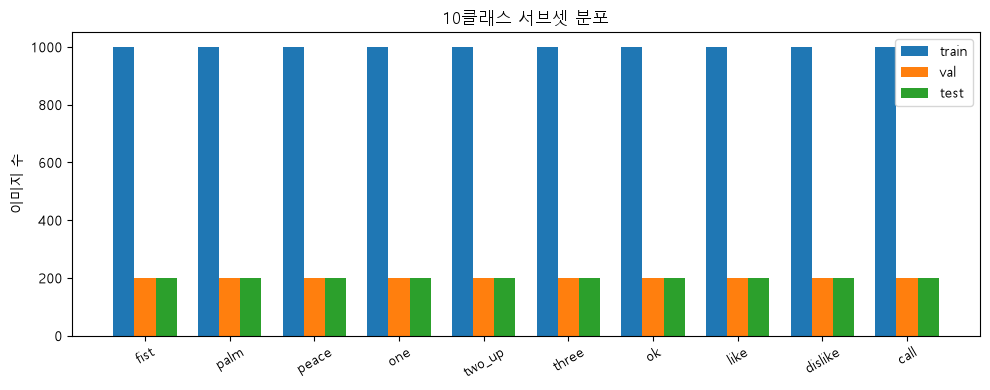

In [14]:
# [시각화 1] 클래스 불균형을 한눈에 보기 위한 막대 그래프다.
# 어떤 클래스만 매우 적으면 모델이 그 제스처를 충분히 배우지 못할 수 있다.
x = np.arange(len(CLASS_NAMES))  # 0~9를 각 클래스 막대의 가운데 위치로 사용
width = 0.25
plt.figure(figsize=(10, 4))

# 같은 클래스에서 train/val/test 막대가 겹치지 않도록 x를 조금씩 좌우로 이동한다.
plt.bar(x - width, split_counts['train'], width, label='train')
plt.bar(x, split_counts['val'], width, label='val')
plt.bar(x + width, split_counts['test'], width, label='test')
plt.xticks(x, CLASS_NAMES, rotation=30)
plt.ylabel('이미지 수')
plt.title('10클래스 서브셋 분포')
plt.legend()
plt.tight_layout()  # 글자와 그래프가 그림 밖으로 잘리지 않게 여백 자동 조정

# 발표 자료에서 재사용할 수 있도록 models 폴더에 저장하고 노트북에도 표시한다.
plt.savefig(MODEL_DIR / 'class_distribution.png', dpi=120)
plt.show()


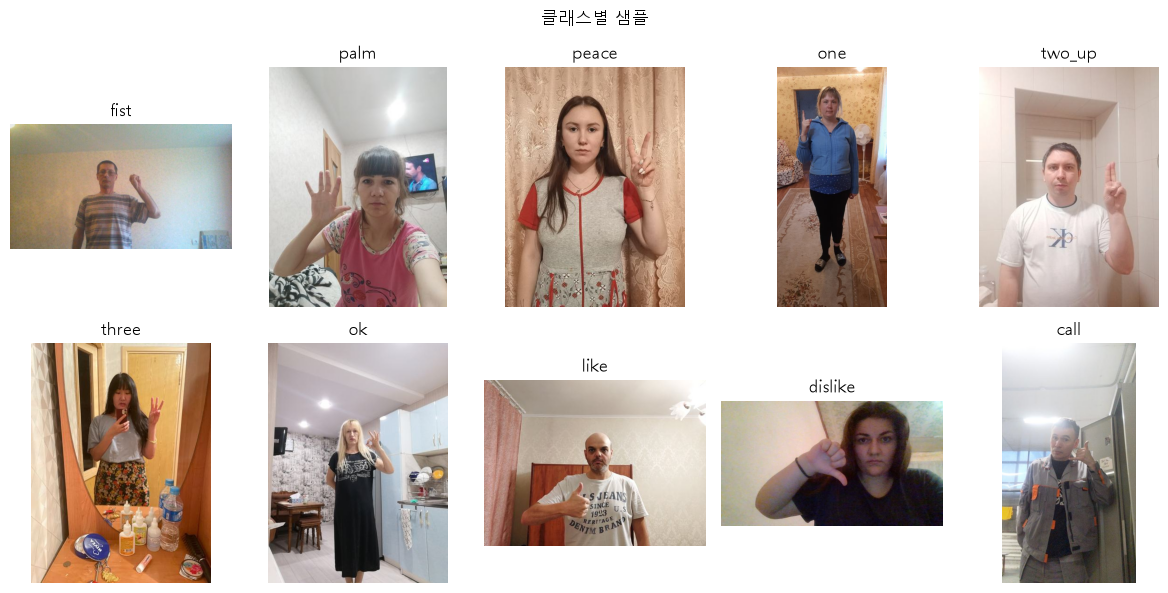

In [15]:
# 클래스별 샘플 이미지
plt.figure(figsize=(12, 6))
train_labs = list((OUT_YOLO / 'labels' / 'train').glob('*.txt'))
for i, name in enumerate(CLASS_NAMES):
    picked = None
    for lab_path in train_labs:
        for line in lab_path.read_text(encoding='utf-8').splitlines():
            if int(line.split()[0]) == i:
                for ext in ('.jpg', '.jpeg', '.png'):
                    cand = OUT_YOLO / 'images' / 'train' / f'{lab_path.stem}{ext}'
                    if cand.exists():
                        picked = cand
                        break
                break
        if picked is not None:
            break
    img = cv2.imread(str(picked))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # OpenCV는 BGR, matplotlib는 RGB
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(name)
    plt.axis('off')
plt.suptitle('클래스별 샘플')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'sample_grid.png', dpi=120)
plt.show()



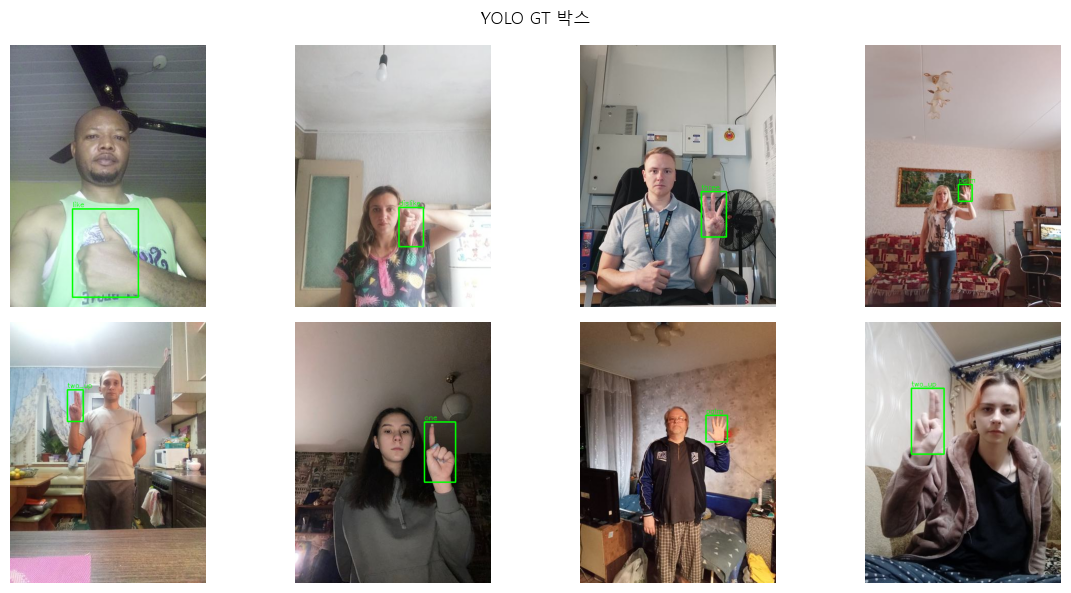

In [16]:
# 학습 전에 정답(Ground Truth, GT) 박스가 손에 정확히 붙는지 검사한다.
# 좌표 변환이 틀리면 모델 설정이 좋아도 잘못된 정답을 배우므로 이 검사가 매우 중요하다.
val_imgs = sorted((OUT_YOLO / 'images' / 'val').glob('*.jpg'))
rng = np.random.default_rng(0)
# replace=False는 같은 이미지를 중복 선택하지 않는다는 뜻이다.
picks = rng.choice(len(val_imgs), size=min(8, len(val_imgs)), replace=False)

plt.figure(figsize=(12, 6))
for i, idx in enumerate(picks):
    img_path = val_imgs[int(idx)]
    lab_path = OUT_YOLO / 'labels' / 'val' / (img_path.stem + '.txt')
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]  # NumPy 이미지 shape은 높이, 너비, 채널 순서

    for line in lab_path.read_text(encoding='utf-8').splitlines():
        cid, xc, yc, bw, bh = line.split()
        cid, xc, yc, bw, bh = int(cid), float(xc), float(yc), float(bw), float(bh)

        # YOLO의 0~1 중심 좌표를 OpenCV가 요구하는 픽셀 모서리 좌표로 되돌린다.
        x1 = int((xc - bw / 2) * W)
        y1 = int((yc - bh / 2) * H)
        x2 = int((xc + bw / 2) * W)
        y2 = int((yc + bh / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, CLASS_NAMES[cid], (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1)

    plt.subplot(2, 4, i + 1)
    # OpenCV는 BGR, Matplotlib는 RGB이므로 빨강·파랑이 바뀌지 않게 변환한다.
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
plt.suptitle('YOLO GT 박스')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'gt_check.png', dpi=120)
plt.show()



In [17]:
# [모델 로드] 학습에 필요한 입력 파일과 결과 경로를 한곳에 정리한다.
DATA_YAML = OUT_YOLO / 'dataset.yaml'       # 앞에서 만든 데이터 설명서
run_dir = MODEL_DIR / 'yolo' / RUN_NAME    # 로그·그래프·가중치가 저장될 실험 폴더
best_pt = run_dir / 'weights' / 'best.pt'  # val 성능이 가장 좋았던 epoch의 PyTorch 가중치

print('시작 가중치:', WEIGHTS)
print('dataset.yaml 존재:', DATA_YAML.exists())
print('기존 best.pt 존재:', best_pt.exists())

# 이 한 줄은 학습을 시작하지 않는다. 네트워크 구조와 COCO 사전학습 가중치를 메모리에 불러온다.
# n 모델의 파라미터 수가 s보다 적어 파일 크기와 연산량이 작다.
model = YOLO(WEIGHTS)


시작 가중치: yolov8n.pt
dataset.yaml 존재: True
기존 best.pt 존재: True


In [18]:
if (not RETRAIN) and best_pt.exists():
    print('이미 학습된 가중치를 사용합니다:', best_pt)
    print('다시 학습하려면 RETRAIN = True')
else:
    results = model.train(
        data=str(DATA_YAML),  # train/val 위치와 10개 클래스 이름
        imgsz=IMGSZ,         # 모든 이미지를 640 기준으로 리사이즈/letterbox
        epochs=EPOCHS,       # train 전체를 최대 50번 반복
        batch=BATCH,         # 한 번의 가중치 업데이트에 사용할 이미지 수
        device=DEVICE,       # 0번 CUDA GPU
        workers=WORKERS,     # Windows Jupyter 안정성을 위해 데이터 작업 프로세스 0개

        # AMP는 float32와 float16을 섞어 정확도 손실을 작게 유지하면서 GPU 속도·메모리를 절약한다.
        amp=True,
        cache=False,         # 모든 이미지를 RAM에 올리지 않아 메모리 부족을 피한다.

        # 데이터 증강: 4장 mosaic는 사용하고, mixup/copy-paste는 손 모양이 부자연스러워 껐다.
        mosaic=1.0,
        mixup=0.0,
        copy_paste=0.0,
        close_mosaic=10,     # 마지막 10 epoch는 실제 사진 형태에 맞춰 마무리하도록 mosaic를 끈다.

        patience=20,         # val 성능이 20 epoch 동안 개선되지 않으면 조기 종료
        optimizer='auto',    # Ultralytics가 모델과 epoch에 맞는 optimizer/학습률을 선택
        project=str(MODEL_DIR / 'yolo'),
        name=RUN_NAME,
        exist_ok=True,       # 같은 실험 폴더를 사용할 수 있게 함
        plots=True,          # results, confusion matrix, F1 curve 등을 자동 저장
        pretrained=True,     # COCO에서 배운 백본 지식을 유지한 채 파인튜닝
        seed=SEED,
        verbose=True,        # epoch별 손실과 지표를 화면에 자세히 출력
    )
    print('가장 좋은 가중치:', best_pt)


이미 학습된 가중치를 사용합니다: t:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights\best.pt
다시 학습하려면 RETRAIN = True


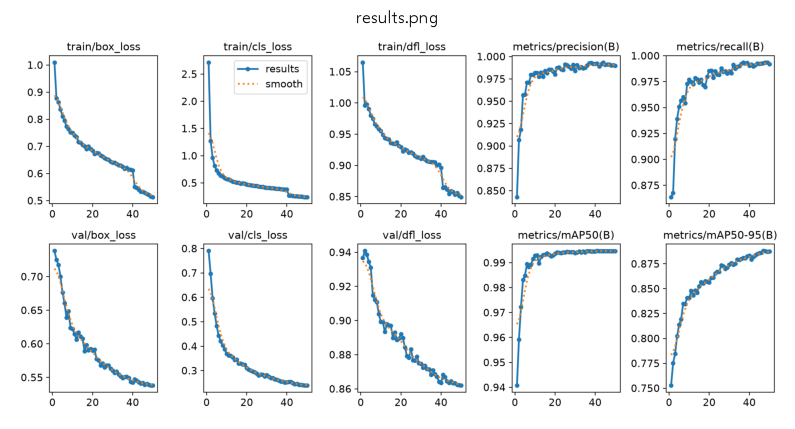

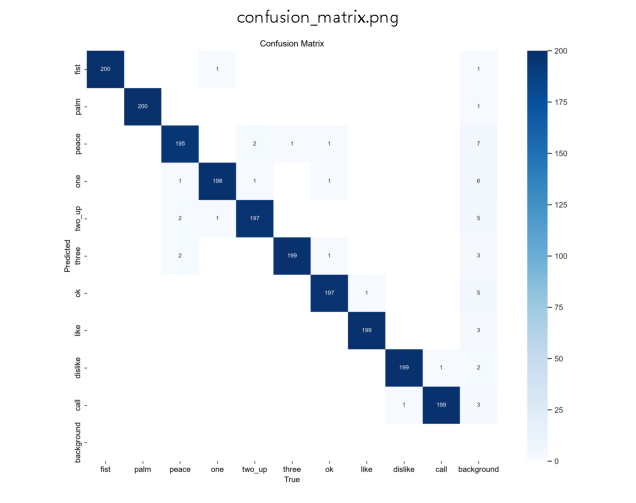

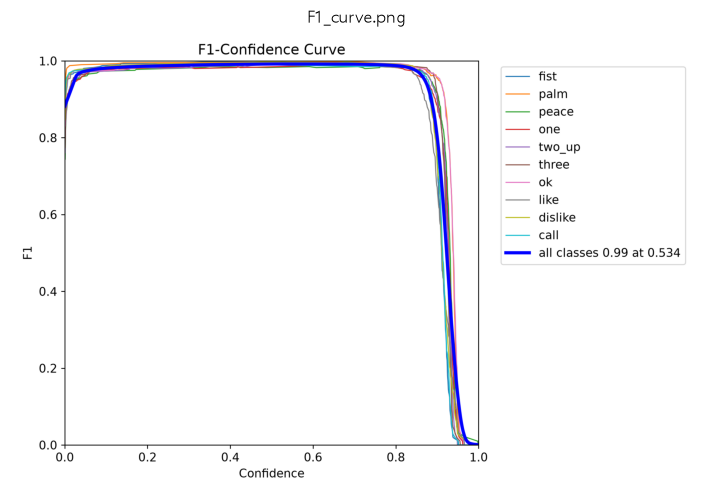

In [19]:
# [학습 결과 읽기] Ultralytics가 학습 중 자동 저장한 핵심 그림을 노트북에 표시한다.
# results.png: epoch에 따른 loss와 Precision/Recall/mAP 변화
# confusion_matrix.png: 실제 클래스와 예측 클래스가 어디서 혼동됐는지
# F1_curve.png: confidence 기준에 따라 Precision과 Recall의 균형(F1)이 어떻게 변하는지
for fname in ('results.png', 'confusion_matrix.png', 'F1_curve.png'):
    p = run_dir / fname
    if p.exists():
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')  # 그래프 자체에 축이 이미 있으므로 Matplotlib 바깥 축은 숨긴다.
        plt.title(fname)
        plt.show()
    else:
        print('파일 없음:', p)



In [20]:
# [최종 평가] 학습 시작 가중치(yolov8n.pt)가 아니라 우리가 만든 best.pt를 불러온다.
best_model = YOLO(str(best_pt))

# 메서드 이름은 val이지만 split='test'를 주었으므로 dataset.yaml의 test 폴더를 평가한다.
# 여기서는 역전파나 가중치 업데이트가 일어나지 않는다. 오직 예측과 정답을 비교한다.
metrics = best_model.val(
    data=str(DATA_YAML),
    split='test',
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,  # confusion matrix와 PR/F1 관련 그림도 저장
)

# mp/mr의 m은 클래스별 값을 평균(mean)했다는 뜻이다.
print('precision:', float(metrics.box.mp))
print('recall:', float(metrics.box.mr))
print('mAP50:', float(metrics.box.map50))
print('mAP50-95:', float(metrics.box.map))



Ultralytics YOLOv8.2.103  Python-3.12.6 torch-2.13.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3080, 10240MiB)
Model summary (fused): 168 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs


val: Scanning T:\AIStudy\handsProj\works\data\hagrid10\yolo\labels\test.cache... 2000 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2000/2000 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 125/125 [00:10<00:00, 11.56it/s]


                   all       2000       2000      0.992       0.99      0.994       0.88
                  fist        200        200          1      0.985      0.993      0.848
                  palm        200        200      0.995          1      0.995      0.927
                 peace        200        200      0.995      0.994      0.995      0.895
                   one        200        200      0.992       0.98      0.994      0.881
                two_up        200        200      0.987          1      0.994      0.899
                 three        200        200      0.998      0.995      0.995      0.884
                    ok        200        200      0.995       0.98      0.995      0.901
                  like        200        200      0.975      0.984      0.993      0.864
               dislike        200        200      0.989          1      0.995      0.863
                  call        200        200       0.99       0.98      0.993      0.842
Speed: 0.1ms preproce

In [21]:
# [한 장 예측] test 이미지에서 모델이 어떤 배열을 돌려주는지 단계별로 확인한다.
test_imgs = sorted((OUT_YOLO / 'images' / 'test').glob('*'))
img_path = test_imgs[0]                 # 예제를 단순하게 보여 주려고 첫 이미지 한 장 선택
image_cv = cv2.imread(str(img_path))    # OpenCV는 이미지를 BGR 순서의 NumPy 배열로 읽는다.
image_for_display = image_cv.copy()     # 원본 배열을 보존하고 복사본에만 박스를 그린다.

# conf=0.25보다 낮은 후보는 버린다. 낮추면 더 많이 찾지만 오검출도 늘 수 있다.
results = best_model.predict(source=image_cv, save=False, verbose=False, conf=0.25)

# 한 이미지에 여러 손이 검출될 수 있지만 이 예제에서는 가장 confidence가 높은 하나를 표시한다.
best_object = None
if results and results[0].boxes:
    for result in results:
        # Tensor는 GPU에 있을 수 있어 .cpu()로 옮긴 뒤 익숙한 NumPy 배열로 바꾼다.
        boxes = result.boxes.xyxy.cpu().numpy()       # 각 행: 왼쪽x, 위y, 오른쪽x, 아래y
        classes = result.boxes.cls.cpu().numpy()      # 각 박스의 클래스 번호
        confidences = result.boxes.conf.cpu().numpy() # 각 박스의 신뢰도 0~1
        class_names = result.names                    # 클래스 번호를 이름으로 바꾸는 표

        # zip으로 같은 순번의 박스·클래스·신뢰도를 하나씩 함께 꺼낸다.
        for box, cls, conf in zip(boxes, classes, confidences):
            class_name = class_names[int(cls)]
            if best_object is None or conf > best_object['confidence']:
                best_object = {'class_name': class_name, 'confidence': conf, 'box': box}

best_guess = '탐지된 객체 없음'
if best_object:
    class_name = best_object['class_name']
    confidence = best_object['confidence']
    x1, y1, x2, y2 = [int(v) for v in best_object['box']]
    print('클래스:', class_name, '신뢰도:', round(float(confidence), 2), '좌표:', (x1, y1, x2, y2))

    label = f'{class_name}: {confidence:.2f}'
    cv2.rectangle(image_for_display, (x1, y1), (x2, y2), (0, 255, 0), 2)
    (w, h), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.rectangle(image_for_display, (x1, y1 - h - baseline), (x1 + w, y1), (0, 255, 0), -1)
    cv2.putText(image_for_display, label, (x1, y1 - baseline), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
    best_guess = class_name



클래스: ok 신뢰도: 0.93 좌표: (118, 34, 224, 171)


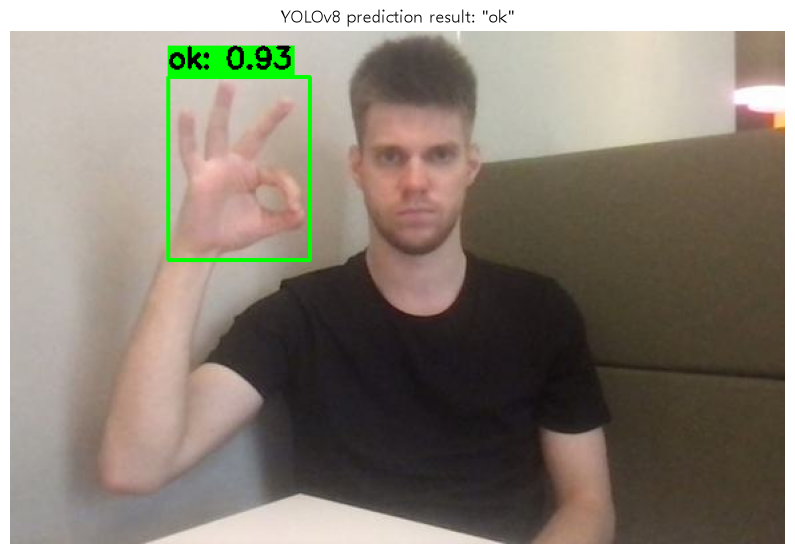

In [22]:
# 결과 이미지를 BGR에서 RGB로 변환하여 Matplotlib로 출력
image_result_rgb = cv2.cvtColor(image_for_display, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 8))
plt.imshow(image_result_rgb)
plt.axis('off')
plt.title(f'YOLOv8 prediction result: "{best_guess}"')
plt.show()



Results saved to t:\AIStudy\handsProj\works\models\yolo\test_preview


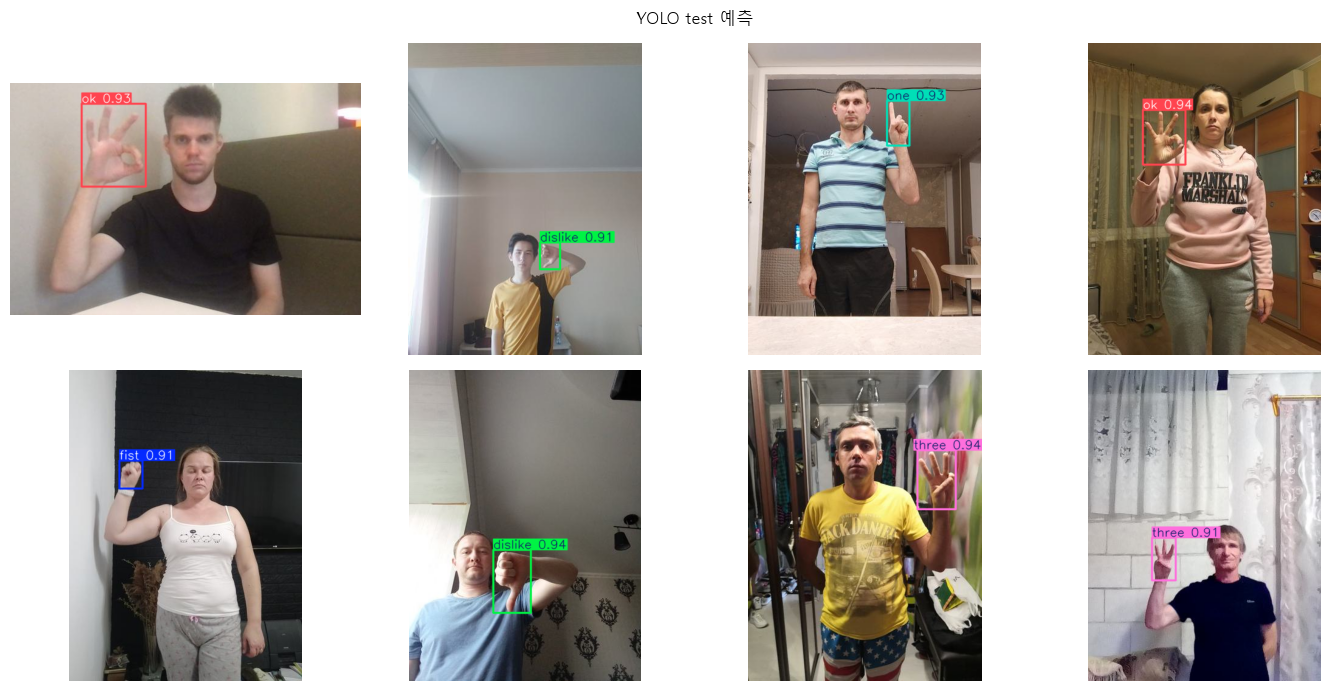

In [23]:
# 테스트 이미지 여러 장 미리보기
pred_results = best_model.predict(
    source=[str(p) for p in test_imgs[:8]],
    imgsz=IMGSZ,
    device=DEVICE,
    conf=0.25,
    save=True,
    project=str(MODEL_DIR / 'yolo'),
    name='test_preview',
    exist_ok=True,
)

plt.figure(figsize=(14, 7))
for i, r in enumerate(pred_results[:8]):
    img = r.plot()
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
plt.suptitle('YOLO test 예측')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'yolo_pred_grid.png', dpi=120)
plt.show()



In [24]:
# [ONNX 변환] 평가에 사용한 best_model을 웹 실행 형식으로 내보낸다.
export_path = best_model.export(
    format='onnx',
    imgsz=320,      # demo.py의 letterbox와 반드시 같은 한 변 크기
    opset=12,       # ONNX 연산 규격 버전
    simplify=True,  # 계산 그래프를 가능한 범위에서 단순화
    dynamic=False,  # 배치 1, 320x320 고정 입력
    device=DEVICE,
)
export_path = Path(export_path)
print('Ultralytics가 만든 ONNX:', export_path)

# demo.py가 항상 models 폴더에서 찾도록 최종 파일을 정해진 위치에 복사한다.
dst_pt = MODEL_DIR / 'best.pt'       # 다시 평가·변환할 때 쓸 PyTorch 버전
dst_onnx = MODEL_DIR / 'best.onnx'   # 브라우저가 실제 추론에 쓸 버전
shutil.copy2(best_pt, dst_pt)
shutil.copy2(export_path, dst_onnx)

# 웹은 모델 출력의 0,1,... 번호만으로 클래스 이름을 알 수 없어 별도 설명 파일이 필요하다.
# conf=0.55는 55%보다 낮은 후보를 버려 흔들리는 오검출을 줄이는 기준이다.
(MODEL_DIR / 'labels.json').write_text(
    json.dumps(
        {'names': CLASS_NAMES, 'imgsz': 320, 'conf': 0.55},
        ensure_ascii=False,  # 한글이 있다면 \uXXXX 대신 읽을 수 있는 문자로 저장
        indent=2,            # 사람이 확인하기 좋게 들여쓰기
    ),
    encoding='utf-8',
)
print('pt  :', dst_pt)
print('onnx:', dst_onnx)


Ultralytics YOLOv8.2.103  Python-3.12.6 torch-2.13.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3080, 10240MiB)

PyTorch: starting from 't:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights\best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 14, 2100) (5.9 MB)

ONNX: starting export with onnx 1.22.0 opset 12...


W0902 02:26:40.506000 36812 Lib\site-packages\torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0902 02:26:41.209000 36812 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
T:\AIStudy\Python312\Lib\copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be

ONNX: slimming with onnxslim 0.1.34...
ONNX: export success  4.4s, saved as 't:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights\best.onnx' (11.5 MB)

Export complete (4.5s)
Results saved to T:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights
Predict:         yolo predict task=detect model=t:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights\best.onnx imgsz=320  
Validate:        yolo val task=detect model=t:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights\best.onnx imgsz=320 data=T:\AIStudy\handsProj\works\data\hagrid10\yolo\dataset.yaml  
Visualize:       https://netron.app
Ultralytics가 만든 ONNX: t:\AIStudy\handsProj\works\models\yolo\gesture_yolov8n10\weights\best.onnx
pt  : t:\AIStudy\handsProj\works\models\best.pt
onnx: t:\AIStudy\handsProj\works\models\best.onnx


In [25]:
# [ONNX 스모크 테스트] 정확도를 다시 평가하는 셀이 아니라 파일이 실제로 열리고 계산되는지 확인한다.
try:
    import onnxruntime as ort

    # CUDA가 가능하면 먼저 사용하고, 아니면 CPU로 자동 대체한다.
    sess = ort.InferenceSession(
        str(dst_onnx),
        providers=['CUDAExecutionProvider', 'CPUExecutionProvider'],
    )
    inp = sess.get_inputs()[0]
    print('onnx input:', inp.name, inp.shape, inp.type)

    # 실제 사진 대신 모양만 같은 임의 숫자 배열을 넣는다.
    # [1, 3, 320, 320] = 이미지 1장, RGB 3채널, 높이 320, 너비 320이다.
    dummy = np.random.rand(1, 3, 320, 320).astype(np.float32)
    outs = sess.run(None, {inp.name: dummy})
    print('onnx outputs:', [o.shape for o in outs])
except Exception as e:
    # 로컬 onnxruntime 패키지 문제여도 export 파일 자체는 이미 저장되었을 수 있다.
    print('onnxruntime 확인 실패 (파일은 저장됨):', e)

print('다음 단계: python demo.py')



onnx input: images [1, 3, 320, 320] tensor(float)
onnx outputs: [(1, 14, 2100)]
다음 단계: python demo.py


과거 7클래스 n val last {'epoch': 50, 'P': 0.99372, 'R': 0.99252, 'mAP50': 0.99464, 'mAP50-95': 0.89566, 'cls': 0.22262}
과거 7클래스 s val last {'epoch': 50, 'P': 0.99557, 'R': 0.99345, 'mAP50': 0.99476, 'mAP50-95': 0.90389, 'cls': 0.20424}


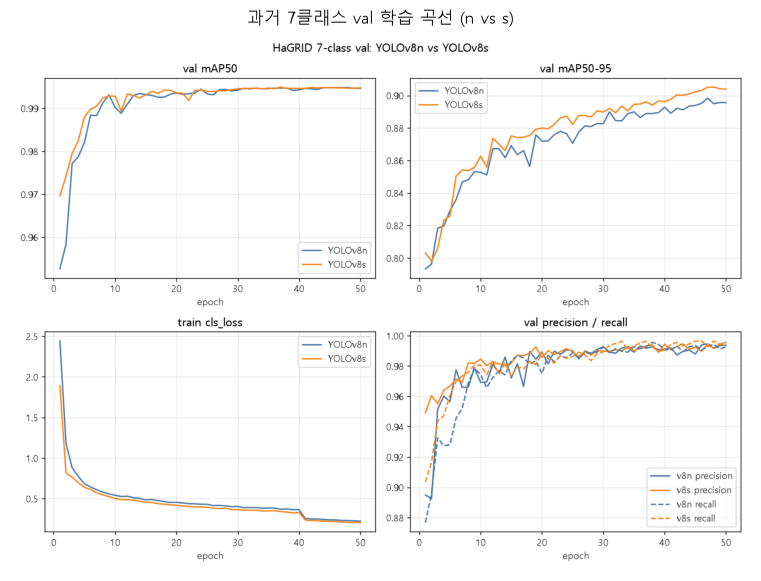

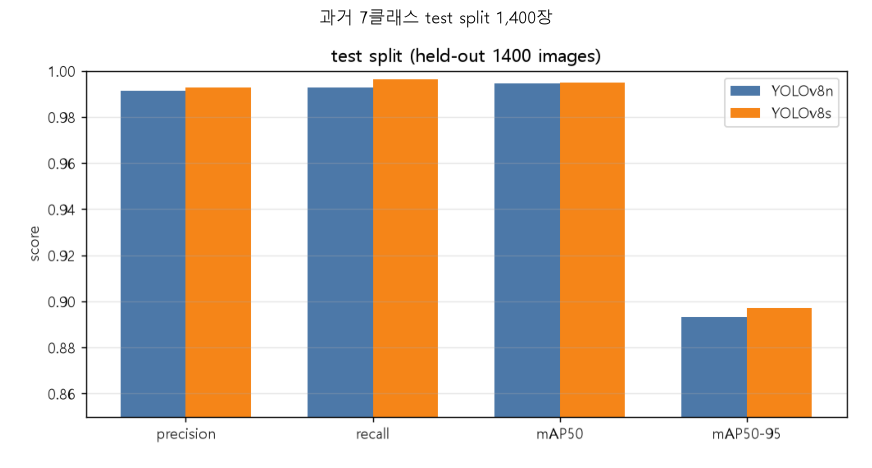

[과거 7클래스] test n: P=0.9915 R=0.9927 mAP50=0.9946 mAP50-95=0.8933
[과거 7클래스] test s: P=0.9926 R=0.9963 mAP50=0.9949 mAP50-95=0.8971
small이 조금 높지만 mAP50 차이는 0.0003뿐이어서 실시간성이 좋은 nano를 선택했다.


In [ ]:
# [추가 실험] nano(n)와 small(s)의 마지막 학습 로그를 같은 항목으로 비교한다.
import csv

def last_metrics(csv_path):
    """Ultralytics results.csv의 마지막 epoch에서 발표에 필요한 값만 숫자로 반환한다."""
    with open(csv_path, encoding='utf-8') as f:
        rows = list(csv.DictReader(f))

    # CSV 열 이름 주변에 공백이 있을 수 있어 strip으로 제거한다.
    d = {k.strip(): v.strip() for k, v in rows[-1].items()}
    return {
        'epoch': int(float(d['epoch'])),
        'P': float(d['metrics/precision(B)']),
        'R': float(d['metrics/recall(B)']),
        'mAP50': float(d['metrics/mAP50(B)']),
        'mAP50-95': float(d['metrics/mAP50-95(B)']),
        'cls': float(d['train/cls_loss']),
    }

# 두 실험의 조건이 같아야 모델 크기 차이를 공정하게 비교할 수 있다.
# 이 경로는 과거 7클래스 실험 결과이므로 파일이 없으면 부록만 건너뛴다.
n_csv = MODEL_DIR / 'yolo' / 'gesture_yolov8n' / 'results.csv'
s_csv = MODEL_DIR / 'yolo' / 'gesture_yolov8s' / 'results.csv'
if n_csv.exists() and s_csv.exists():
    n_last = last_metrics(n_csv)
    s_last = last_metrics(s_csv)
    print('과거 7클래스 n val last', n_last)
    print('과거 7클래스 s val last', s_last)
else:
    print('과거 n/s CSV가 없어 로그 비교를 건너뜁니다.')

# 저장해 둔 과거 비교 그림도 존재할 때만 표시한다.
for fname, title in (
    ('n_vs_s_compare.png', '과거 7클래스 val 학습 곡선 (n vs s)'),
    ('n_vs_s_test_bar.png', '과거 7클래스 test split 1,400장'),
):
    p = MODEL_DIR / fname
    if not p.exists():
        print('비교 그림 없음:', p)
        continue
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(11, 7))
    plt.imshow(img)
    plt.axis('off')
    plt.title(title)
    plt.show()

# 아래 숫자도 현재 10클래스 결과가 아니라 모델 선택 근거로 사용한 과거 7클래스 test 결과다.
print('[과거 7클래스] test n: P=0.9915 R=0.9927 mAP50=0.9946 mAP50-95=0.8933')
print('[과거 7클래스] test s: P=0.9926 R=0.9963 mAP50=0.9949 mAP50-95=0.8971')
print('small이 조금 높지만 mAP50 차이는 0.0003뿐이어서 실시간성이 좋은 nano를 선택했다.')